In [2]:
# Initialize Otter
import otter
grader = otter.Notebook("hwk2-task2-salmon.ipynb")

# Task 2: Wrangling Alaska salmon catch data 

## Instructions 

- First, update the following cell to have a link to *your* Homework 2 GitHub repository:

**UPDATED LINK**
https://github.com/eowen19/eds220-hwk2


- Review the [complete rubric for this task](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0) before starting.

- **Meaningful commits should be made every time you finish a major step.** We'll check your repository and view the commit history.

- **Every code cell should have a comment.** Err on the side of commenting too much for now. Comments should follow best practices.

- **Do not update the top cell with the `otter` import**, this is used internally for grading.

## Acknowledgments

This exercise is based on the [Cleaning and Wrangling Data in R lesson by the NCEAS Learning Hub](https://learning.nceas.ucsb.edu/2023-06-delta/session_11.html).


> Halina Do-Linh, Carmen Galaz García, Matthew B. Jones, Camila Vargas Poulsen. 2023. Open Science Synthesis training Week 1. NCEAS Learning Hub & Delta Stewardship Council.


## About the data

In this task you will use simplified data from the Alaska Department of Fish & Game containing commercial salmon catch data from 1878 to 1997. The original data can be accessed from the KNB repository:

> [Mike Byerly. (2016). Alaska commercial salmon catches by management region (1886-1997).](https://knb.ecoinformatics.org/view/df35b.304.2) Gulf of Alaska Data Portal. df35b.304.2.

The simplified dataset is in CSV format in the homework repository and has the following columns:

| Column | Description |
| ------ | ----------- | 
| Region | Region code |
| Year | Year fish were caught |
| notesRegCode | Notes and comments |
| Species | Species of salmon caught |
| Catch | Commercial catches of salmon species (in thousands of fish) |

## COMPLETE WORKFLOW

You will use the next code cell to complete the last exercise in the task. Leave it blank for now. 

In [2]:
# FINAL CODE



## 1

a. Use this code cell to import the data from the `salmon_data.csv` as `catch_data`. Look at the head of the data frame. 

<!-- BEGIN QUESTION -->



In [4]:
# Load libraries
import pandas as pd

In [5]:
# Load data
catch_data = pd.read_csv('data/salmon_data.csv')

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

b. Use this code cell to make some other preliminary data exploration of your choosing.

In [6]:
# Explore the data using head(), shape, tail()
catch_data.head()
catch_data.shape
catch_data.tail()

,Region,Year,notesRegCode,Species,Catch
8535,NOP,1993,NaN,Chum,135
8536,NOP,1994,NaN,Chum,84
8537,NOP,1995,NaN,Chum,99
8538,NOP,1996,NaN,Chum,68
8539,NOP,1997,NaN,Chum,97


In [7]:
# Explore the data using describe(), unique(), and isna()
catch_data['Species'].describe()
catch_data['Species'].unique()
catch_data['Region'].unique()
catch_data['notesRegCode'].isna().value_counts()

notesRegCode
True     7125
False    1415
Name: count, dtype: int64

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

c. Use this markdown cell to explain why you decided to do the exploration in b. and what information you obtained from doing it.

The catch data contains five columns ('Region', 'Year', 'notesRegCode', 'Species', 'Catch'). 
There are 8539 rows of data, with the first year recorded being 1886, and the last recorded being 1997.
The species listed within the dataset are: Chinook, Sockeye, Coho, Pink, Chum. 
There are 18 regions listed within the dataset. 

<!-- END QUESTION -->

## 2
In the next cell:

a. Store the unique values of the `notesRegCode` column in the `notes_unique` variable. 

In [8]:
# Use .unique() to idenitify unique values within the catch_data dataframe 
notes_unique = catch_data['notesRegCode'].unique()
print(notes_unique)

[nan 'Includes Yakutat catches' 'Yakutat catch included in No SE AK catch'
 'Estimated from canned production, probably sockeye' 'No fishery'
 'Bering River catches included in Copper River catches'
 'Includes Bering River catches; estimated from canned'
 'Includes Bering River catches'
 'Coho and pink catch estimated from canned production'
 'Includes Bering River; coho and pink estimated fro canned'
 'Pink catch estimated from canned'
 'Includes Bering River; coho pink and chum estimated from canned'
 'Includes Bering River; pink estimated from canned'
 'Includes Bering River; pink and chum estimated from canned'
 'Includes Copper River catches'
 'Includes Copper River catches; coho catch porbably mostly pinks'
 'Eshamy District only' 'Estimated from canned; excludes Resurrection Bay'
 'Estimated from canned production' 'No Resurrection Bay fishery'
 'Resurrection bay contribution estimated from canned production'
 'No reported catch'
 'Sockeye and pink and 9922 chum from Port Claren

In [9]:
grader.check("q2a")

q2a results: All test cases passed!

b. Update the data frame so it doesn't include the `notesRegCode` column. Verify the column is no longer in the data frame.

In [10]:
# Use .drop() to drop the notesRegCode column from the data frame
catch_data = catch_data.drop(columns = 'notesRegCode')

In [11]:
grader.check("q2b")

q2b results: All test cases passed!

<!-- BEGIN QUESTION -->

## 3
Does each column have the expected data type? Use this code cell to obtain this information and write your answer in the next markdown cell.


No, while Region (object), Year (int64), and Species (object) are fairly expected, Catch (object) is unexpected, as Catch is saved as a numerical value, and thus would be expected to have the data type of int64. 

In [12]:
catch_data.dtypes

Region     object
Year        int64
Species    object
Catch      object
dtype: object

<!-- END QUESTION -->

## 4 
The following cell shows a first attempt at updating the `Catch` column to be of data type `int64` instead of `object`. Converting from one data type to another is often called **casting**. 

To do it we use the [`astype()`](https://pandas.pydata.org/pandas-docs/stable/reference/api/pandas.Series.astype.html) method for `pandas.Series`. The `astype()` method does not modify the `pandas.Series` in place.

Run the next cell and read the end of the error message closely.

In [13]:
catch_data['Catch'].astype('int64')

ValueError: invalid literal for int() with base 10: 'I'

## 5 

The previous error tells us there is a value 'I' (as in the letter 'I') that could not be converted to integer type. It turns out the original data set was created from a PDF which was automatically converted into a CSV file and this 'I' value should be 1.

In the next cell find the row(s) causing this issue. Show the filtered row(s) as the output. Store your answer in the `catch_I` variable. `catch_I` should have one observation and contain the following columns: Region, Year, Species, Catch. It should contain the original index number in order to pass the test. 

In [14]:
catch_I = catch_data[catch_data['Catch']== 'I']
catch_I 

,Region,Year,Species,Catch
400,GSE,1955,Chinook,I


In [15]:
grader.check("q5")

q5 results: All test cases passed!

## 6
In the next cell:

1. Update the value of I to 1.
2. Access the row you updated to verify the value was changed and store this single row in the `catch_1` variable. 

<!-- BEGIN QUESTION -->



In [16]:
catch_data.at[400, 'Catch'] = 1
catch_data.loc[400]

Region         GSE
Year          1955
Species    Chinook
Catch            1
Name: 400, dtype: object

In [17]:
catch_1 = catch_data.at[400, 'Catch'] = 1
# Print catch_1
catch_1

1

<!-- END QUESTION -->

## 7
In the next cell:

1. Update the `Catch` column in `catch_data` to be of type `int64`.
2. Confirm you have updated the data type. Store the type of the `Catch` column in the `catch_column_type` variable.

In [18]:
catch_data_type = catch_data['Catch'].astype('int64')
catch_column_type = catch_data_type.dtypes
catch_column_type

dtype('int64')

In [19]:
grader.check("q7")

q7 results: All test cases passed!

<!-- BEGIN QUESTION -->

## 8
Create a data frame with the average salmon catch per region. HINT: use `groupby()`. Store your data frame in a new variable called `avg_region`


In [20]:
avg_region = catch_data.groupby(['Species', 'Region']).count()
avg_region

Year  Catch
Species Region             
Chinook ALU       87     87
        BER      102    102
        BRB      114    114
        CHG      110    110
        CKI      105    105
...              ...    ...
Sockeye PWS      109    109
        SOP       90     90
        SSE      112    112
        YAK       96     96
        YUK       79     79

[90 rows x 2 columns]

In [21]:
grader.check("q8")

q8 results: All test cases passed!

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 9 

Use the data frame you created in 8 to make a bar graph of the estimated average salmon catches by region from 1878 to 1997. The bars in the graph should be ordered by magnitude (increasing or decreasing is ok). Add a title to your graph and update the axes labels if needed (check the units for the salmon catch). 

In [ ]:
(penguins.groupby(['island','year'])
         .size()
         .sort_values()
         .plot(kind='barh',
                title='Penguins surveyed at the Palmer Archipelago',
                xlabel='Number of penguins',
                ylabel='Island, Year')
         )

<Axes: title={'center': 'Species of Salmon by Region'}, xlabel='Number of Salmon', ylabel='Species, Region'>

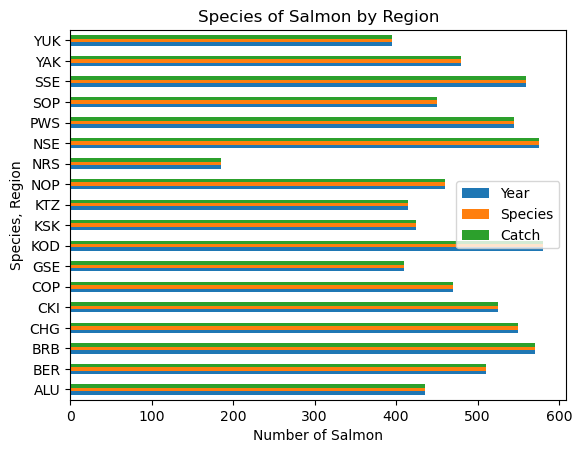

In [29]:
(catch_data.groupby(['Region']).count()
    .plot(kind='barh',
             title = 'Species of Salmon by Region', 
             xlabel = 'Number of Salmon', 
             ylabel = 'Species, Region')
)

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

## 10

Write a brief description with key takeaways from the plot. Your answer should use the complete names for the management areas instead of their codes. You can find what each code stands for in the [original data repository](https://knb.ecoinformatics.org/view/df35b.304.2#df35b.303.1).

<!-- END QUESTION -->

## 11

Collect all the relevant code into the first blank cell of the notebook titled "COMPLETE WORKFLOW". This single cell will have the end-to-end workflow: from importing libraries and loading the data, to producing the graph. The *only* output of this cell should be the graph you produced in the previous exercise. Further guidance on what to include in this final workflow is in the [assignment rubric](https://docs.google.com/document/d/1x0BoU6IH4cnOR1-n7i9CYQ9wUC37yDpYlQ4j6rCfcsU/edit?tab=t.0).

---

To double-check your work, the cell below will rerun all of the autograder tests.

In [ ]:
grader.check_all()